In [2]:

import sys
import numpy
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

Exercise 1: Replicate PCA analysis
To perform PCA, you will use the function PCA from the sklearn.decomposition module to create a PCA model object. This object can then be trained on your data and provide transformed coordinates for your data. You will then need to plot the first two principal components of your PCA. For this section, you will be using the replicate data as you should see how the timepoints and replicates relate to each other.

Use the function you wrote to plot the first two PCs for the replicate data. How similar do the replicates look to each other? Would you expect them to be more or less similar than samples from different time points?

ANSWER:

This PCA plot tells me that the reps collected by time are somewhat clustered. the blue and gray time points are less seem to have more variance. 

Exercise 2: Data filtering and more PCA
Filter all three datasets. Once you have the filtered data, use your PCA function to plot the first to PCs of the filtered replicates. Do they look any different?

ANSWER: The 2 PCAs have a similar structure, but the axis is slightly different. it looks like PC1 and PC2 have show variance among the samples after filtering.

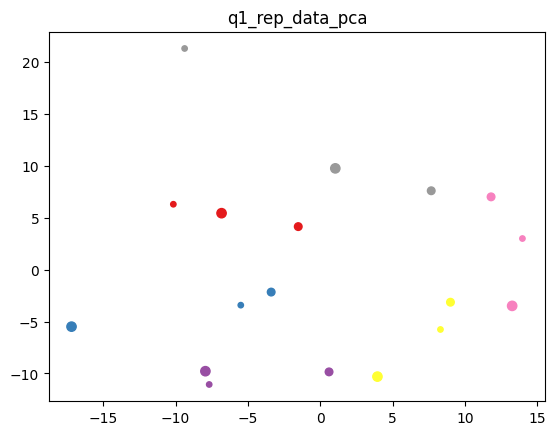

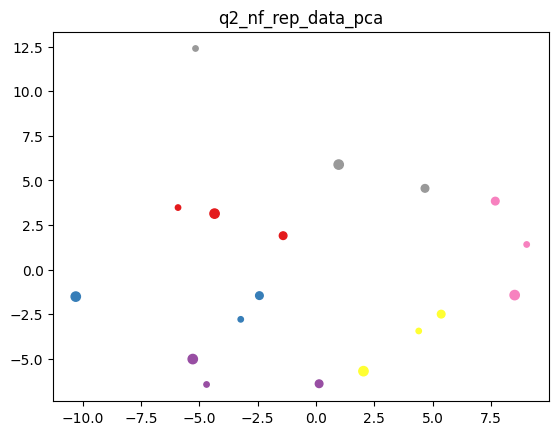

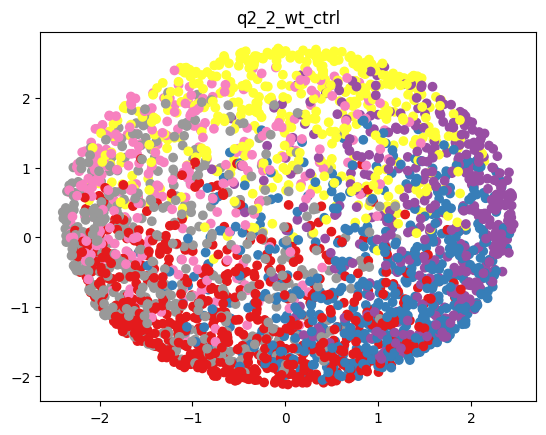

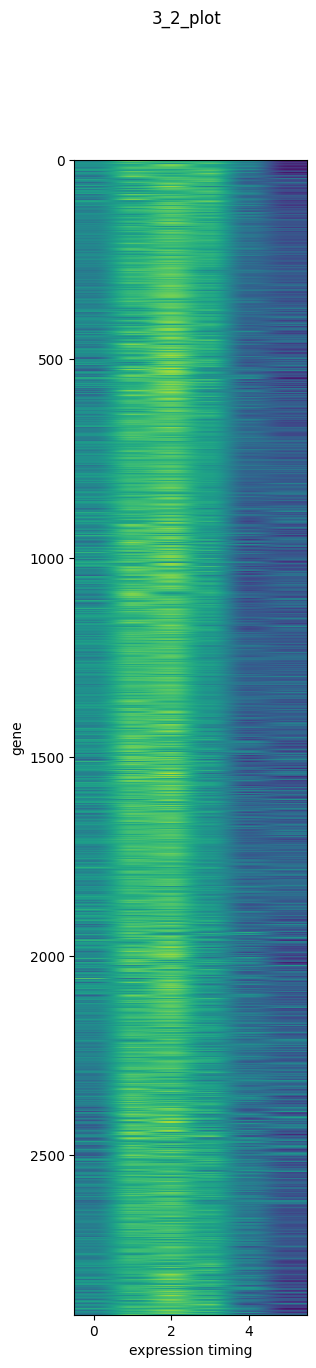

1.26.4


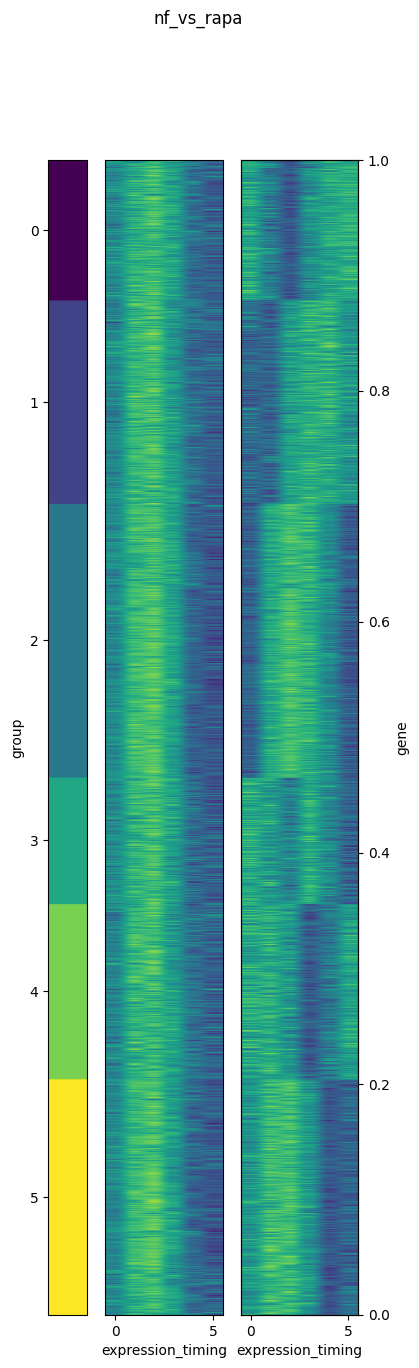

In [ ]:
#PCA function
#I did ask HOP for help with understanding the strcuture of this PCA in addition to the documentation. One thing i had needed clarification was where PCA function should live relative to def_main
#  I added some of the comments that were used to described the commands from the skit.learn documentation. For question 2,  
def pca_plot(data, times, reps, title):
    #transpose the matrix. it makes the x axis timepoints and the y axis genes to reduce
    X = data.T
    #create model and include the argument random_state=42. This will make sure you get the same answer each time
    pca = PCA(n_components=2, random_state = 42)
    #Fit the model with X and apply the dimensionality reduction on X
    X_reduced = pca.fit_transform(X)
    #scatter plot with color points by the sampling time
    plt.scatter(X_reduced[:,0], X_reduced[:,1], c=times, cmap='Set1', s=reps*15)
    #Add title 
    plt.title(title)
    #save plot to week 5 directory
    plt.savefig(f'/Users/cmdb/qb26-answers/week5/{title}.png') #hop said to add f so that each PCA could use the title variable
    plt.show()

#QUESTION_2.2
#write a function that can find and plot the first two PCs of the WT_NF_Ctrl data. In order to give the plot some context, also accept an argument for specifying a color for each gene via a 1D array.
def pca_wt_ctrl(data, colors, title):
    #do not transpose the matrix to make x axis genes. this will reduce the timepoints instead on the y axis.
    X = data
    #create model and include the argument random_state=42. This will make sure you get the same answer each time
    pca = PCA(n_components=2, random_state = 42)
    #in the PCA function, include the argument random_state=42. This will make sure you get the same answer as us
    X_reduced = pca.fit_transform(X)
    #scatter plot with color points by the sampling time. switch times to colors.
    plt.scatter(X_reduced[:,0], X_reduced[:,1], c=colors, cmap='Set1')
    #Add title 
    plt.title(title)
    #save plot to week 5 directory
    plt.savefig(f'/Users/cmdb/qb26-answers/week5/{title}.png') #hop said to add f so that each PCA could use the title variable
    plt.show()
    #return the first two sets of PC coordinates as you will need them later
    return X_reduced

def normalize_data(data):
    """
    Function to normalize data along the second axis of a 2D array.

    Parameters:
    -----------
    data : ndarray
           A 2D matrix containing sample data where the rows are samples and columns are features.

    Returns:
    --------
    norm_data : ndarray
                An array of the sample shape and data type as the original data with values normalized along the second axis.
    """
    norm_data = numpy.copy(data)
    norm_data -= numpy.mean(norm_data, axis=1, keepdims=True)
    norm_data /= numpy.std(norm_data, axis=1, keepdims=True)
    return norm_data

def PCA_analysis(data):
    pca=PCA(2)
    PC_coords - pca.fit_transform(data)

def plot_hm(*data, xlabel='', ylabel='', title='', orderby=None, showgroups=False, fname=None):
    """
    Function for plotting heatmap/matrix style data.

    Parameters:
    -----------
    data : ndarray(s)
           The array or arrays should be 2D with rows plotted along the y-axis and columns plotted along the x-axis.
           If multiple arrays are passed as positional arguments, they need to have the same number of rows.
    xlabel : str
           An x-axis label for the plotted data
    ylabel : str
           A y-axis label for the plotted data
    title : str
           A title to add above the plot
    orderby : ndarray
           A list of indices or group labels for ordering the data along the x-axis. If None, the data order is not changed
    showgroups : bool
           An indicator whether the group labels passed to `orderby` should be plotted as an additional color bar. Ignored if orderby is None.
    fname : str
           A file name to save the plot to. If None, the plot is only displayed but not saved.
    
    Returns:
    --------
    None
    """
    if orderby is None:
        order = numpy.arange(data[0].shape[0])
    else:
        order = numpy.argsort(orderby)
    if orderby is None or not showgroups:
        fig, ax = plt.subplots(1, len(data), figsize=(3, 15))
        if len(data) > 1:
            for i in range(len(data)):
                ax[i].imshow(data[i][order, :], aspect='auto')
                ax[i].set_xlabel(xlabel)
                if i > 0:
                    ax[i].set_yticks([])
            ax[0].set_ylabel(ylabel)
        else:
            ax.imshow(data[0][order, :], aspect='auto')
            ax.set_xlabel(xlabel)
            ax.set_ylabel(ylabel)
    else:
        groups = orderby[order]
        fig, ax = plt.subplots(1, len(data) + 1, width_ratios=[1] + [3] * len(data), figsize=(4, 15))
        if len(data) > 1:
            for i in range(len(data)):
                ax[i + 1].imshow(data[i][order, :], aspect='auto')
                ax[i + 1].set_xlabel(xlabel)
                ax[i + 1].set_ylabel('')
                ax[i + 1].set_yticks([])
        else:
            ax[-1].imshow(data[0][order, :], aspect='auto')
            ax[-1].set_xlabel(xlabel)
            ax[-1].set_ylabel('')
            ax[-1].set_yticks([])
        ax[-1].yaxis.tick_right()
        ax2 = ax[-1].twinx()
        ax2.set_ylabel(ylabel)
        ax[0].set_ylabel('group')
        ax[0].imshow(groups.reshape(-1, 1), aspect='auto')
        bounds = numpy.r_[0, numpy.where(groups[1:] != groups[:-1])[0] + 1, groups.shape[0]] - 0.5
        ax[0].set_yticks((bounds[:-1] + bounds[1:]) / 2)
        ax[0].set_yticklabels([str(i) for i in range(bounds.shape[0] - 1)])
        ax[0].set_xticks([])
    if title:
        plt.suptitle(title)
    if fname is not None:
        plt.savefig(fname, dpi=300, bbox_inches='tight')
    plt.show()


def align_times(data, angle):
    """
    This function takes a 2D matrix of data and a 1D matrix of angles (radians) and shifts data along the second axis (axis=1)
    to align all rows to have an effective angle of zero.

    Parameters:
    -----------
    data : ndarray
           A 2D matrix of data where each row is a sample and each column is a measurement in a cyclical cycle
    angle : ndarray
           A 1D matrix of data of a length equal to the number of rows in data. Angles should be in radians.
           
    Returns:
    --------
    aligned : ndarray
              A new array with data shifted along the second axis to align each row to have an angle of zero
    """
    n = data.shape[1]
    offsets = n - angle * n / (numpy.pi * 2)
    offsets[numpy.where(offsets < 0)] += n
    aligned = numpy.zeros_like(data)
    for i in range(data.shape[0]):
        aligned[i, :] = (numpy.roll(data[i, :], int(numpy.floor(offsets[i]))) * (numpy.ceil(offsets[i]) - offsets[i]) +
                         numpy.roll(data[i, :], int(numpy.ceil(offsets[i]))) * (offsets[i] - numpy.floor(offsets[i])))
    return aligned


#read the counts data and extract sanpling time and replicate info
def main():
    rapa_data = numpy.loadtxt('/Users/cmdb/qb26-answers/week5/WT_NF_Rapa_counts.tsv')
    nf_data = numpy.loadtxt('/Users/cmdb/qb26-answers/week5/WT_NF_Ctrl_counts.tsv')
    nf_rep_data = numpy.loadtxt('/Users/cmdb/qb26-answers/week5/WT_NF_Ctrl_rep_counts.tsv')

    # The row and column names are stored in separate files. The sampling time and replicate can be extracted from the sample names
    genes = numpy.array([name.rstrip() for name in open('/Users/cmdb/qb26-answers/week5/gene_names.txt')])
    sample_labels = numpy.array([name.rstrip().split('\t') for name in open('/Users/cmdb/qb26-answers/week5/samples.txt')])
    times = numpy.array([int(time.split('_')[1]) for time, rep in sample_labels if rep == 1], numpy.int32)
    rep_times = numpy.array([int(time.split('_')[1]) for time, rep in sample_labels], numpy.int32)
    reps = numpy.array([int(rep.split('_')[1]) for time, rep in sample_labels], numpy.int32)

    pca_plot(nf_rep_data, rep_times, reps, 'q1_rep_data_pca')

    #QUESTION_2
    #find the mean and standard deviation of data for each sample using numpy.mean and numpy.std and the argument axis=1 to apply these metrics to each row
    nf_rep_mean = numpy.mean(nf_rep_data, axis=1)
    nf_rep_sd = numpy.std(nf_rep_data, axis =1)
    rapa_mean = numpy.mean(rapa_data, axis=1)
    rapa_sd = numpy.std(rapa_data, axis=1)
    nf_mean = numpy.mean(nf_data, axis=1)
    nf_sd = numpy.std(nf_data, axis =1)

#only keep genes with a mean expression about 0.85 and a scaled standard deviation (i.e. std / mean) greater than 0.115
    #Scaled deviation for nf_rep
    nf_rep_scaled_dev =  nf_rep_sd/nf_rep_mean
    nf_rep_rule1 = nf_rep_scaled_dev > 0.115
    nf_rep_rule2 = nf_rep_mean > 0.85

    nf_rep_cuttoff = nf_rep_rule1 & nf_rep_rule2 #hop told me to switch comma to &

    #Scaled deviation for rapa
    rapa_scaled_dev =  rapa_sd/rapa_mean
    rapa_rule1 = rapa_scaled_dev > 0.115
    rapa_rule2 = rapa_mean > 0.85

    rapa_cuttoff = rapa_rule1 & rapa_rule2

    #Scaled deviation for nf_data
    nf_scaled_dev =  nf_sd/nf_mean
    nf_rule1 = nf_scaled_dev > 0.115
    nf_rule2 = nf_mean > 0.85

    nf_cuttoff = nf_rule1 & nf_rule2

    #nf_rep
    nf_rep_filtered_data = nf_rep_data[nf_rep_cuttoff, :]

    #rapa
    rapa_filtered_data = rapa_data[nf_rep_cuttoff, :]

    #nf_data
    nf_filtered_data = nf_data[nf_rep_cuttoff, :]
 
    #FOR QUESTION 2.1
    pca_plot(nf_rep_filtered_data, rep_times, reps, 'q2_nf_rep_data_pca')
    #pca_plot(rapa_filtered_data, times, rep_times, 'q2_rapa_data_pca')
    #pca_plot(nf_filtered_data, times, rep_times, 'q1_nf_filtered_data_pca')

    #Normalize data. For this step, i initally put this outside of the main again, which is why hop had to correct me to understand my error
    normalized_nf = normalize_data(nf_filtered_data)
    normalized_rapa = normalize_data(rapa_filtered_data)
    #to help understand what the data mean, color the points by their time of peak expression
    peak = numpy.argmax(normalized_nf, axis=1)
    
    #QUESTION 2.3
    #If everything has gone correctly, you should see that your PCA plot looks like a circle with a relatively smooth color transition around the circle, almost like a clock. 
    #If we make the assumption that that is what is being represented, then the angle of each gene’s point from the origin should be its expression timing
    #pca_wt_ctrl(normalized_nf, peak,'q2_2_wt_ctrl')

    #QUESTION 3.1
    #Order expression times and plot data
    #Calculate the angle from the first two PC corrdinates 
    nf_coordinates = pca_wt_ctrl(normalized_nf, peak, 'q2_2_wt_ctrl')
    #find the angles 
    y_coords = nf_coordinates[:,1]
    x_coords = nf_coordinates[:,0]
    angles = numpy.arctan2(y_coords, x_coords)

    nf_aligned = align_times(normalized_nf, angles)
    rapa_aligned = align_times(normalized_rapa, angles)

    plot_hm(nf_aligned, xlabel='expression timing', ylabel='gene', title='3_2_plot', orderby=angles, showgroups=False, fname=None)

    #I had the same issue as Cole so i changed the helper script for the align_times function sent in the quantbio channel. i don't undertand why it needed to be fixed but i have the same version of numpy as cole.
    print(numpy.version.version)

    #K means clustering
    k_means = KMeans(n_clusters=6, init='k-means++', random_state=42).fit_predict(numpy.concatenate((nf_aligned, rapa_aligned), axis=1))

    #def plot_hm(*data, xlabel='', ylabel='', title='', orderby=None, showgroups=False, fname=None)
    #I had several errors with the syntax of this plot, with the main catch from hopgpt was that i didn't pass both datasets. I also didn't know where to put k_means in the argument
    plot_hm(nf_aligned, rapa_aligned, xlabel='expression_timing', ylabel='gene', title='nf_vs_rapa', orderby= k_means, showgroups=True, fname=None),                                           

main()